In [1]:
# Python version
import sys
print(sys.version)

3.12.13 | packaged by Anaconda, Inc. | (main, Mar 19 2026, 20:16:45) [MSC v.1942 64 bit (AMD64)]


In [2]:
# Import key libraries and check versions
import pandas as pd
import numpy as np
import sklearn
import shap
import irapy
import matplotlib

print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("sklearn:", sklearn.__version__)
print("shap:", shap.__version__)
print("irapy:", irapy.__version__)
print("matplotlib:", matplotlib.__version__)

pandas: 2.3.3
numpy: 2.2.5
sklearn: 1.8.0
shap: 0.51.0
irapy: 0.1.2
matplotlib: 3.10.9


In [3]:
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.svm import SVR
from sklearn.linear_model import Ridge
from sklearn.inspection import PartialDependenceDisplay
from sklearn.inspection import permutation_importance
from sklearn.pipeline import Pipeline
from irapy import repeated_ira

In [4]:
n_cpus = 12

In [5]:
data = fetch_california_housing(as_frame= True)
X = data.data
y = data.target
print(data.DESCR)

print(y)
feature_name_map = {
    "MedInc": "Median Income",
    "HouseAge": "House Age",
    "AveRooms": "Average Rooms",
    "AveBedrms": "Average Bedrooms",
    "Population": "Population",
    "AveOccup": "Average Occupancy",
    "Latitude": "Latitude",
    "Longitude": "Longitude"
}

X_ = X.rename(columns = feature_name_map)

y_ = y.rename("Median House Value")

df = pd.concat([X_,y_], axis=1)

df.describe().T

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib repository.
https://www.dcc.fc.up.pt/~ltorgo/Regression/cal_housing.html

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per ce

,count,mean,std,min,25%,50%,75%,max
Median Income,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
House Age,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
Average Rooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
Average Bedrooms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
Average Occupancy,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
Median House Value,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


In [6]:
#  Train models

models = {
    'GB': GradientBoostingRegressor(random_state=42),

    'MLP': Pipeline([
        ('scaler', StandardScaler()),
        ('MLP', MLPRegressor(random_state=42, max_iter=500)),
    ]),

    'RF': RandomForestRegressor(random_state=42),

    'RR': Pipeline([
        ('scaler', StandardScaler()),
        ('RR', Ridge()),
    ]),

    'SVR': Pipeline([
        ('scaler', StandardScaler()),
        ('SVR', SVR()),
    ])
}

trained_models = {}
performance = {}

print("Model Performance (R²):")
print("-" * 50)

for name, model in models.items():
    model.fit(X_, y_)
    score = model.score(X_,y_)
    trained_models[name] = model
    performance[name] = score

print(performance)

Model Performance (R²):
--------------------------------------------------
{'GB': 0.8033237500356992, 'MLP': 0.8020538895280646, 'RF': 0.9739753020308555, 'RR': 0.6062326414700455, 'SVR': 0.7502397399037284}


In [7]:
# Repeated IRA

final_ira_result = []

for name, model in trained_models.items():

    repeated_ira_result = repeated_ira(input_data=X_, model=model, n_jobs=n_cpus)

    print("#"*80)
    print(name)
    display(repeated_ira_result)

    sel = repeated_ira_result.iloc[:,1:].copy()
    sel.columns = [f"{name}_{col}" for col in sel.columns]
    final_ira_result.append(sel)

repeated_ira_df = pd.concat(final_ira_result, axis=1)
repeated_ira_df.insert(0,'predictor',X_.columns)
print("\n--- Final Repeated IRA Result Table ---")
repeated_ira_df

################################################################################
GB


,predictor,mean_ira,ci_lower_ira,ci_upper_ira
0,Median Income,3.075110,3.043272,3.106985
1,House Age,0.257034,0.235686,0.280714
2,Average Rooms,1.313864,1.293942,1.336362
3,Average Bedrooms,0.322112,0.294511,0.352652
4,Population,0.117344,0.095426,0.140422
5,Average Occupancy,1.203537,1.142068,1.259635
6,Latitude,2.139235,2.068966,2.219614
7,Longitude,2.127800,2.076270,2.184266


################################################################################
MLP


,predictor,mean_ira,ci_lower_ira,ci_upper_ira
0,Median Income,2.712850,2.644707,2.776967
1,House Age,0.579355,0.532266,0.638362
2,Average Rooms,34.481998,34.316924,34.627983
3,Average Bedrooms,5.505628,5.340945,5.637505
4,Population,1.699636,1.635436,1.769222
5,Average Occupancy,2.716579,2.615265,2.842661
6,Latitude,3.584554,3.336471,3.847337
7,Longitude,5.605245,5.432568,5.821865


################################################################################
RF


,predictor,mean_ira,ci_lower_ira,ci_upper_ira
0,Median Income,3.153925,3.096033,3.196166
1,House Age,0.493571,0.430104,0.574498
2,Average Rooms,0.437105,0.409784,0.467767
3,Average Bedrooms,0.323213,0.296081,0.347427
4,Population,0.428208,0.392125,0.470889
5,Average Occupancy,1.055962,0.937598,1.187438
6,Latitude,1.464463,1.365872,1.555802
7,Longitude,1.391237,1.317542,1.472626


... (2 outputs left out)

################################################################################
SVR


,predictor,mean_ira,ci_lower_ira,ci_upper_ira
0,Median Income,3.769670,3.723636,3.819468
1,House Age,0.689213,0.611851,0.760771
2,Average Rooms,1.631305,1.578828,1.694320
3,Average Bedrooms,1.641877,1.582107,1.718703
4,Population,1.237383,1.188795,1.297630
5,Average Occupancy,3.096274,2.950327,3.233767
6,Latitude,2.865580,2.727672,2.999188
7,Longitude,4.062831,3.818782,4.245245



--- Final Repeated IRA Result Table ---


,predictor,GB_mean_ira,GB_ci_lower_ira,GB_ci_upper_ira,MLP_mean_ira,MLP_ci_lower_ira,MLP_ci_upper_ira,RF_mean_ira,RF_ci_lower_ira,RF_ci_upper_ira,RR_mean_ira,RR_ci_lower_ira,RR_ci_upper_ira,SVR_mean_ira,SVR_ci_lower_ira,SVR_ci_upper_ira
0,Median Income,3.075110,3.043272,3.106985,2.712850,2.644707,2.776967,3.153925,3.096033,3.196166,6.331936,6.331936,6.331936,3.769670,3.723636,3.819468
1,House Age,0.257034,0.235686,0.280714,0.579355,0.532266,0.638362,0.493571,0.430104,0.574498,0.481489,0.481489,0.481489,0.689213,0.611851,0.760771
2,Average Rooms,1.313864,1.293942,1.336362,34.481998,34.316924,34.627983,0.437105,0.409784,0.467767,15.131747,15.131747,15.131747,1.631305,1.578828,1.694320
3,Average Bedrooms,0.322112,0.294511,0.352652,5.505628,5.340945,5.637505,0.323213,0.296081,0.347427,21.747998,21.747998,21.747998,1.641877,1.582107,1.718703
4,Population,0.117344,0.095426,0.140422,1.699636,1.635436,1.769222,0.428208,0.392125,0.470889,0.141151,0.141151,0.141151,1.237383,1.188795,1.297630
5,Average Occupancy,1.203537,1.142068,1.259635,2.716579,2.615265,2.842661,1.055962,0.937598,1.187438,4.705732,4.705732,4.705732,3.096274,2.950327,3.233767
6,Latitude,2.139235,2.068966,2.219614,3.584554,3.336471,3.847337,1.464463,1.365872,1.555802,3.961840,3.961840,3.961840,2.865580,2.727672,2.999188
7,Longitude,2.127800,2.076270,2.184266,5.605245,5.432568,5.821865,1.391237,1.317542,1.472626,4.359386,4.359386,4.359386,4.062831,3.818782,4.245245


In [8]:
# Permutation importance

importance_dict = {}
for name, model in trained_models.items():
    print(name)
    result = permutation_importance(model, X_, y_, n_repeats=10,scoring = 'neg_mean_absolute_error', random_state=42, n_jobs=n_cpus)
    importance_dict[(name, 'mean')] = result.importances_mean
    importance_dict[(name, 'std')] = result.importances_std

importance_df = pd.DataFrame(importance_dict, index=X_.columns)
importance_df.columns = pd.MultiIndex.from_tuples(importance_df.columns)
importance_df = importance_df.sort_values(by=(list(trained_models.keys())[0], 'mean'), ascending=False)
importance_df

GB
MLP
RF
RR
SVR


GB                 MLP                  RF            \
                       mean       std      mean       std      mean       std   
Median Income      0.489521  0.002485  0.347386  0.002701  0.629812  0.002874   
Latitude           0.446008  0.003030  0.880673  0.005447  0.505613  0.002860   
Longitude          0.406089  0.003166  0.830865  0.006574  0.450430  0.002158   
Average Occupancy  0.124698  0.001106  0.160268  0.001992  0.299013  0.001969   
House Age          0.021749  0.000331  0.061922  0.000697  0.140562  0.001445   
Average Rooms      0.011077  0.000191  0.102203  0.000878  0.115201  0.000598   
Average Bedrooms   0.008395  0.000421  0.062770  0.001151  0.059868  0.000567   
Population         0.001780  0.000102  0.021876  0.000529  0.055730  0.000528   

                         RR                 SVR            
                       mean       std      mean       std  
Median Income      0.515959  0.002599  0.501387  0.003345  
Latitude           0.639832  0.002888  0.761473  0.004345  
Longitude          0.617767  0.004788  0.732101  0.005749  
Average Occupancy  0.001219  0.000081  0.080439  0.001204  
House Age          0.012234  0.000612  0.057004  0.000802  
Average Rooms      0.034140  0.000630  0.063972  0.001050  
Average Bedrooms   0.042846  0.001034  0.042877  0.000833  
Population         0.000013  0.000026  0.016052  0.000603

In [9]:
# SHAP value

shap_dict = {}
for name, model in trained_models.items():
    print(name)
    X_sample = shap.sample(X_, 500, random_state=42)
    explainer = shap.Explainer(model.predict, X_sample)
    shap_values = explainer(X_sample)
    shap_dict[(name, 'mean')] = np.abs(shap_values.values).mean(axis=0)
    shap_dict[(name, 'std')] = np.abs(shap_values.values).std(axis=0)

shap_df = pd.DataFrame(shap_dict, index=X_.columns)
shap_df.columns = pd.MultiIndex.from_tuples(shap_df.columns)
shap_df

GB


ExactExplainer explainer: 501it [00:18, 19.04it/s]                         


MLP


ExactExplainer explainer: 501it [00:10,  1.27s/it]                         


RF


ExactExplainer explainer: 501it [01:58,  3.87it/s]                         


RR
SVR


ExactExplainer explainer: 501it [3:58:10, 28.58s/it]                           


GB                 MLP                  RF            \
                       mean       std      mean       std      mean       std   
Median Income      0.532275  0.530857  0.402216  0.385100  0.480296  0.507484   
House Age          0.050829  0.053694  0.063960  0.079416  0.061201  0.084796   
Average Rooms      0.047535  0.037838  0.121919  0.235138  0.060195  0.051349   
Average Bedrooms   0.036683  0.029408  0.041703  0.127125  0.027576  0.035172   
Population         0.008428  0.024804  0.036980  0.033782  0.023530  0.059348   
Average Occupancy  0.199253  0.169489  0.245373  0.207153  0.216485  0.202833   
Latitude           0.515787  0.241817  0.896500  0.351790  0.401457  0.229036   
Longitude          0.421144  0.328224  0.726768  0.551009  0.304792  0.255338   

                         RR                 SVR            
                       mean       std      mean       std  
Median Income      0.628565  0.673466  0.527274  0.519397  
House Age          0.097002  0.063720  0.076928  0.092100  
Average Rooms      0.121328  0.175948  0.098870  0.090342  
Average Bedrooms   0.062888  0.152913  0.060876  0.067576  
Population         0.002970  0.002885  0.024954  0.026092  
Average Occupancy  0.002086  0.001739  0.136902  0.119353  
Latitude           0.821466  0.348064  0.795667  0.278417  
Longitude          0.753222  0.401776  0.687188  0.434270

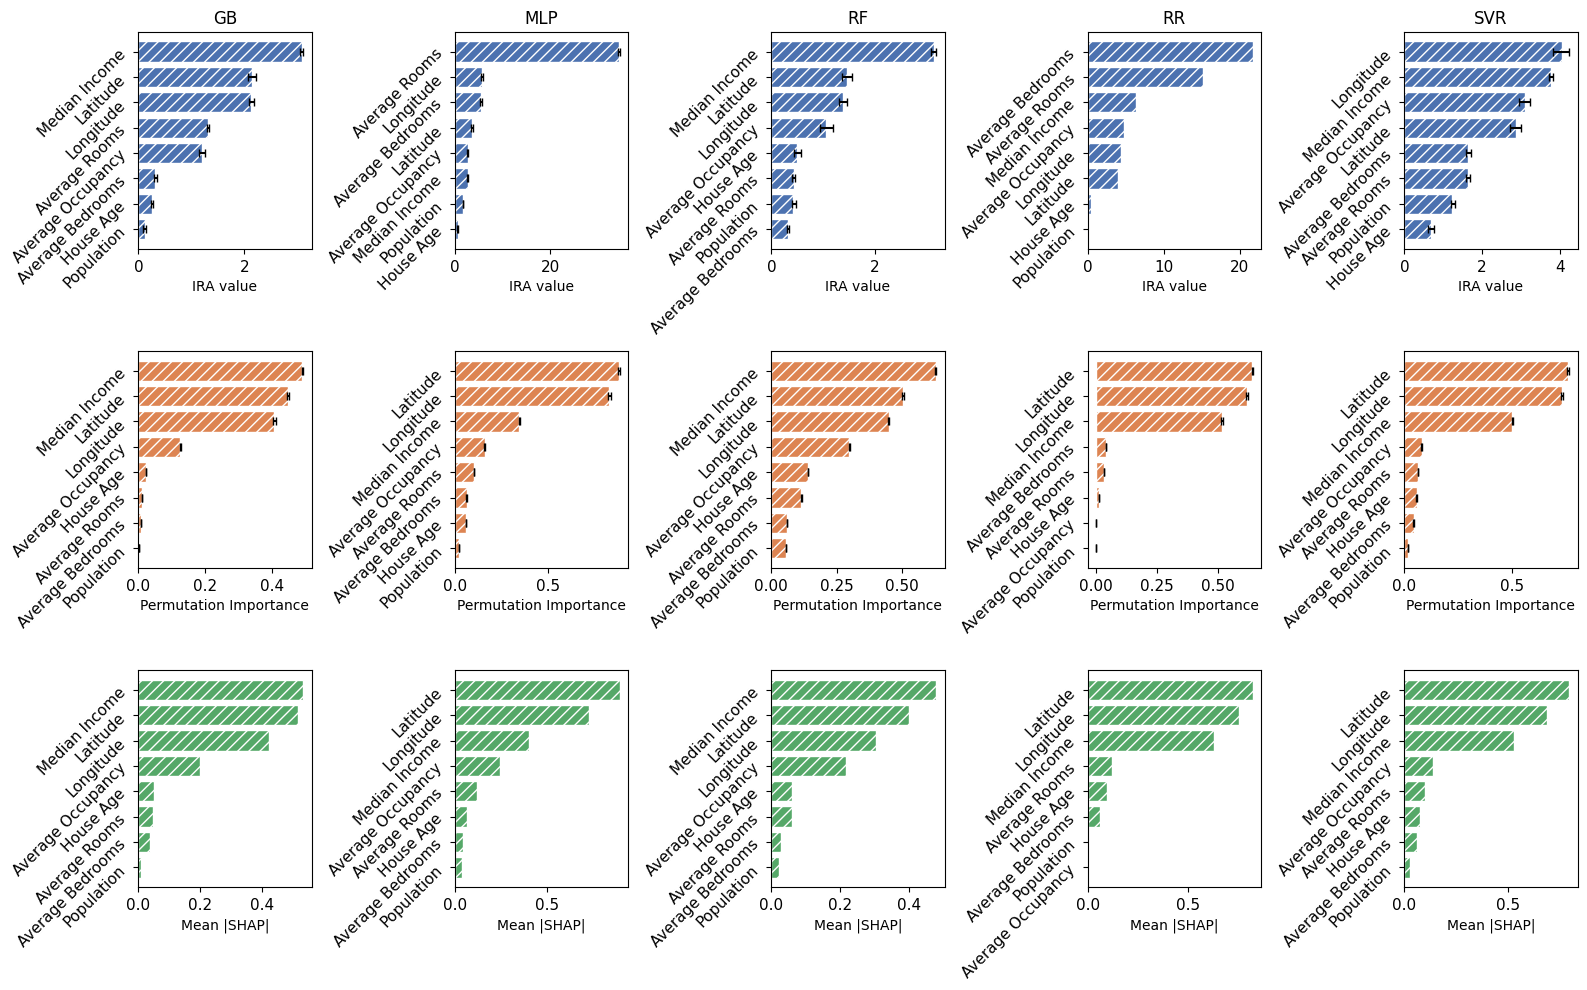

In [10]:
fig, axes = plt.subplots(
    nrows=3,
    ncols=5,
    figsize=(16, 10),
    sharey=False,
    sharex=False
)

ira_color = "#4C72B0"
perm_color = "#DD8452"
shap_color = "#55A868"

for col, model in enumerate(models):

    # =====================================================
    # Row 1: IRA
    # =====================================================
    ira_df_plot = pd.DataFrame({
        "feature": repeated_ira_df["predictor"],
        "mean": repeated_ira_df[f"{model}_mean_ira"],
        "lower": repeated_ira_df[f"{model}_ci_lower_ira"],
        "upper": repeated_ira_df[f"{model}_ci_upper_ira"]
    })

    # SORT FEATURES
    ira_df_plot = ira_df_plot.sort_values(
        by="mean",
        ascending=False
    ).reset_index(drop=True)

    ira_mean = ira_df_plot["mean"]
    ira_lower = ira_df_plot["lower"]
    ira_upper = ira_df_plot["upper"]
    ira_features = ira_df_plot["feature"]

    if col != 3:
        ira_xerr = np.vstack([
            ira_mean - ira_lower,
            ira_upper - ira_mean
        ])

        bars0 = axes[0, col].barh(
            ira_features,
            ira_mean,
            xerr=ira_xerr,
            capsize=3,
            color=ira_color,
            edgecolor='white'
        )
    else:
        bars0 = axes[0, col].barh(
            ira_features,
            ira_mean,
            color=ira_color,
            edgecolor='white'
        )

    for bar in bars0:
        bar.set_hatch('///')

    axes[0, col].set_title(model)
    axes[0, col].set_xlabel('IRA value')

    # =====================================================
    # Row 2: Permutation Importance
    # =====================================================
    perm_df_plot = pd.DataFrame({
        "feature": importance_df.index,
        "mean": importance_df[(model, "mean")].values,
        "std": importance_df[(model, "std")].values
    })

    # SORT FEATURES
    perm_df_plot = perm_df_plot.sort_values(
        by="mean",
        ascending=False
    ).reset_index(drop=True)

    perm_features = perm_df_plot["feature"]
    perm_mean = perm_df_plot["mean"]
    perm_std = perm_df_plot["std"]

    bars1 = axes[1, col].barh(
        perm_features,
        perm_mean,
        xerr=perm_std,
        capsize=3,
        color=perm_color,
        edgecolor='white'
    )

    for bar in bars1:
        bar.set_hatch('///')

    axes[1, col].set_xlabel('Permutation Importance')

    # =====================================================
    # Row 3: SHAP
    # =====================================================
    shap_df_plot = pd.DataFrame({
        "feature": shap_df.index,
        "mean": shap_df[(model, "mean")].values
    })

    # SORT FEATURES
    shap_df_plot = shap_df_plot.sort_values(
        by="mean",
        ascending=False
    ).reset_index(drop=True)

    shap_features = shap_df_plot["feature"]
    shap_mean = shap_df_plot["mean"]

    bars2 = axes[2, col].barh(
        shap_features,
        shap_mean,
        color=shap_color,
        edgecolor='white'
    )

    for bar in bars2:
        bar.set_hatch('///')

    axes[2, col].set_xlabel('Mean |SHAP|')

# =====================================================
# Formatting
# =====================================================
for ax in axes.flatten():

    ax.tick_params(axis="both", labelsize=11)

    ax.tick_params(
        axis='y',
        labelrotation=45
    )

    # highest feature on top
    ax.invert_yaxis()

plt.tight_layout()

plt.savefig(
    'California_Housing_comparison.jpg',
    dpi=500,
    bbox_inches='tight'
)

plt.show()

GB
MLP
RF
RR
SVR


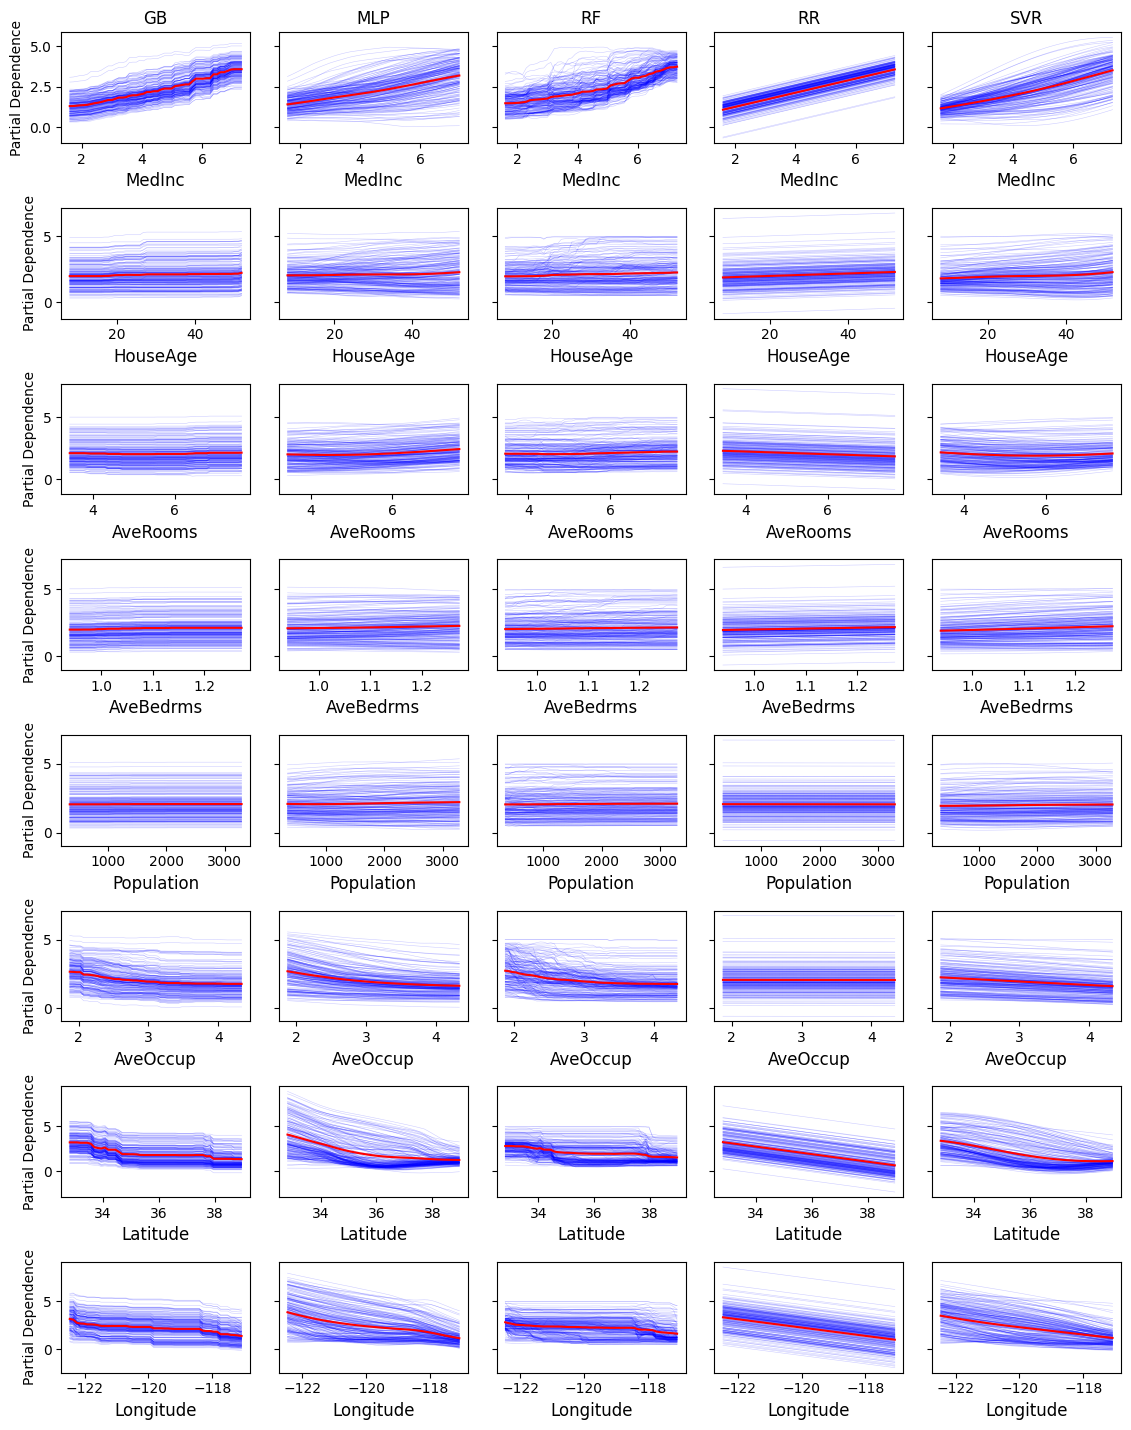

In [11]:
# ─────────────────────────────────────────────────────────────────────
# 5.  Partial Dependence and Individual Conditional Expectation Plots
# ─────────────────────────────────────────────────────────────────────

model_names = list(trained_models.keys())
feature_names = X.columns.tolist()
feature_indices = list(range(len(feature_names)))

# ── Generate and save PDP ──
disp_collection = {}

for name, model in trained_models.items():
    print(name)
    disp = PartialDependenceDisplay.from_estimator(
        model,
        X_,
        features=feature_indices,
        feature_names=feature_names,
        subsample=200,
        kind='both',
        grid_resolution=50,
        random_state=42,
        line_kw={'color': 'red', 'linewidth': 1.5},
        ice_lines_kw={'color': 'blue', 'alpha': 0.2, 'linewidth': 0.4}
    )
    disp_collection[name] = disp
    plt.close()

# ── Plot combined figure ──
n_features = len(feature_names)
n_models = len(model_names)

fig, axes = plt.subplots(
    nrows=n_features,
    ncols=n_models,
    figsize=(2.3*n_models, 1.8*n_features),
    sharey='row'
)

for col_idx, model_name in enumerate(model_names):
    old_disp = disp_collection[model_name]
    old_axes = old_disp.axes_.flatten()

    for row_idx in range(n_features):
        old_ax = old_axes[row_idx]
        new_ax = axes[row_idx, col_idx]

        for line in old_ax.lines:
            new_ax.plot(
                line.get_xdata(),
                line.get_ydata(),
                color=line.get_color(),
                linewidth=line.get_linewidth(),
                alpha=line.get_alpha()
            )

        if row_idx == 0:
            new_ax.set_title(model_name, fontsize=12)

        new_ax.set_xlabel(feature_names[row_idx], fontsize=12)

        if col_idx == 0:
            new_ax.set_ylabel("Partial Dependence")

plt.tight_layout()
plt.savefig(
    'California_Housing_PDP_ICE.jpg',
    dpi=500,
    bbox_inches='tight'
)